# 01a — Single-Domain LoRA Baseline (B2 DocVQA-Only)

Trains B2 (DocVQA-only), syncing checkpoints to private HF Hub (gamusa/crossvqa-checkpoints) and personal Google Drive.


In [1]:
# ==============================================================================
# 1. COLAB SETUP, FAIL-FAST GUARDS, REPO SYNC & FAST DEPS
# ==============================================================================
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

os.environ.pop("HF_HUB_ENABLE_HF_TRANSFER", None)
os.environ["HF_XET_HIGH_PERFORMANCE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTHONUNBUFFERED"] = "1"

REQUIRE_GPU = True          # Set False only for intentional CPU smoke tests
MIN_FREE_DISK_GB = 25.0     # Safety floor for dataset shards + model weights
STAGE_TIMINGS = {}
_t0 = time.perf_counter()

import torch
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / (1024 ** 3)
    sm_major = torch.cuda.get_device_capability(0)[0]
    if sm_major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    print(f"GPU: {props.name} | VRAM: {vram_gb:.1f} GB | bf16: {torch.cuda.is_bf16_supported()} | TF32: {sm_major >= 8}")
else:
    msg = "No CUDA GPU detected. Switch Colab runtime to L4, A100, G4, or T4 (or set REQUIRE_GPU = False)."
    if REQUIRE_GPU:
        raise RuntimeError(msg)
    print("WARNING:", msg)

_disk_probe = Path("/content") if Path("/content").exists() else Path.cwd()
_free_gb = shutil.disk_usage(_disk_probe).free / (1024 ** 3)
print(f"Free disk at {_disk_probe}: {_free_gb:.1f} GB")
if _free_gb < MIN_FREE_DISK_GB:
    raise RuntimeError(f"Insufficient free disk ({_free_gb:.1f} GB < {MIN_FREE_DISK_GB:.1f} GB required).")

def run_streamed(cmd):
    env = os.environ.copy()
    env["PYTHONUNBUFFERED"] = "1"
    proc = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=env,
    )
    for line in proc.stdout:
        print(line, end="", flush=True)
    ret = proc.wait()
    if ret != 0:
        raise subprocess.CalledProcessError(ret, cmd)

if not Path("TRAIN/src").exists():
    if Path("VQA_Final_Thesis/TRAIN/src").exists():
        os.chdir("VQA_Final_Thesis")
    else:
        subprocess.run(["git", "clone", "https://github.com/NhanChanDeo/VQA_Final_Thesis.git"], check=True)
        os.chdir("VQA_Final_Thesis")

subprocess.run(["git", "pull", "origin", "main"], check=True)
print("Working directory:", Path.cwd())

for _k, _v in [("user.name", "Colab Runner"), ("user.email", "colab-runner@users.noreply.github.com")]:
    _chk = subprocess.run(["git", "config", "--get", _k], capture_output=True, text=True)
    if _chk.returncode != 0 or not _chk.stdout.strip():
        subprocess.run(["git", "config", _k, _v], check=True)

_sentinel_dir = Path("/content") if Path("/content").exists() else Path("/tmp")
_deps_sentinel = _sentinel_dir / ".crossvqa_deps_base"
_pkgs = [
    "transformers>=4.49.0", "peft", "bitsandbytes", "accelerate",
    "datasets", "polars", "pyyaml", "safetensors", "huggingface_hub>=0.32.0",
    "hf_xet", "scikit-learn", "qwen-vl-utils",
]
if not _deps_sentinel.exists():
    _uv = shutil.which("uv")
    if _uv:
        subprocess.run([_uv, "pip", "install", "--system", "--quiet", *_pkgs], check=True)
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_pkgs], check=True)
    _deps_sentinel.write_text("ok", encoding="utf-8")
else:
    print("Dependencies already verified in this runtime; skipping install.")

STAGE_TIMINGS["prep_sec"] = round(time.perf_counter() - _t0, 2)
print(f"Bootstrap completed in {STAGE_TIMINGS['prep_sec']:.1f}s")

GPU: Tesla T4 | VRAM: 14.6 GB | bf16: True | TF32: False
Free disk at /content: 235.6 GB
Working directory: /content/VQA_Final_Thesis
Bootstrap completed in 13.1s


In [2]:
# ==============================================================================
# 2. NON-BLOCKING SECRET LOADING & GOOGLE DRIVE CHECKPOINT BACKUP
# ==============================================================================
import os
import time
from getpass import getpass
from pathlib import Path
from huggingface_hub import HfApi

_t0 = time.perf_counter()
PROMPT_FOR_GH_TOKEN = False  # Set True only if GH_TOKEN isn't in Colab Secrets and you want a prompt

# 2A. Interactive masked HF WRITE token (never stored in notebook source/outputs)
HF_TOKEN = os.environ.get("HF_TOKEN") or None
GH_TOKEN = os.environ.get("GH_TOKEN") or None
try:
    from google.colab import userdata
    HF_TOKEN = HF_TOKEN or userdata.get("HF_TOKEN")
    try:
        GH_TOKEN = GH_TOKEN or userdata.get("GH_TOKEN")
    except Exception:
        pass
except Exception:
    pass

if not HF_TOKEN:
    print("Enter your Hugging Face WRITE Token (input is masked and never saved):")
    HF_TOKEN = getpass("HF Write Token: ").strip()

if not GH_TOKEN and PROMPT_FOR_GH_TOKEN:
    GH_TOKEN = getpass("GitHub PAT (masked, optional — press Enter to skip): ").strip() or None

os.environ["HF_TOKEN"] = HF_TOKEN
if GH_TOKEN:
    os.environ["GH_TOKEN"] = GH_TOKEN
assert HF_TOKEN, "HF_TOKEN is required to save/restore private checkpoints."

api = HfApi(token=HF_TOKEN)
user_info = api.whoami()
print(f"Authenticated Hugging Face account: {user_info['name']} | GH_TOKEN loaded: {bool(GH_TOKEN)}")

# 2B. Mount Google Drive for dual-redundant checkpoint backup
GDRIVE_BACKUP_DIR = None
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    drive_ckpt_root = Path("/content/drive/MyDrive/CrossVQA_Checkpoints/ALT_THREE_SPLITS")
    drive_ckpt_root.mkdir(parents=True, exist_ok=True)
    GDRIVE_BACKUP_DIR = str(drive_ckpt_root)
    print(f"Google Drive backup active: {GDRIVE_BACKUP_DIR}")
except Exception as e:
    print(f"Google Drive mount skipped ({e}); continuing with private HF Hub checkpoints only.")

STAGE_TIMINGS["auth_sec"] = round(time.perf_counter() - _t0, 2)

Authenticated Hugging Face account: gamusa | GH_TOKEN loaded: True
Mounted at /content/drive
Google Drive backup active: /content/drive/MyDrive/CrossVQA_Checkpoints/ALT_THREE_SPLITS


In [3]:
# ==============================================================================
# 3. SPLIT-AWARE, IDEMPOTENT NVMe SNAPSHOT OF `three-splits` SHARDS
# ==============================================================================
import time
from pathlib import Path
from huggingface_hub import snapshot_download

_t0 = time.perf_counter()
LOCAL_DATA_DIR = Path("/content/data")
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RESYNC = False

_ALLOW_PATTERNS = ["data/train-*.parquet", "data/validation-*.parquet"]
_REQUIRED_PREFIXES = ["train-", "validation-"]

for ds_name, repo_id in [
    ("docvqa", "gamusa/docvqa-canonical"),
    ("textvqa", "gamusa/textvqa-canonical"),
]:
    target = LOCAL_DATA_DIR / ds_name
    data_dir = target / "data"
    cached_ok = (
        not FORCE_RESYNC
        and data_dir.exists()
        and all(any(data_dir.glob(f"{pfx}*.parquet")) for pfx in _REQUIRED_PREFIXES)
    )
    if cached_ok:
        print(f"Cached on NVMe ({ds_name}): skipping download.")
        continue
    print(f"Syncing {repo_id}@three-splits ({_ALLOW_PATTERNS}) -> {target} ...")
    snapshot_download(
        repo_id=repo_id,
        repo_type="dataset",
        revision="three-splits",
        allow_patterns=_ALLOW_PATTERNS,
        local_dir=str(target),
        max_workers=8,
        token=os.environ.get("HF_TOKEN"),
    )

STAGE_TIMINGS["snapshot_sec"] = round(time.perf_counter() - _t0, 2)
print(f"Snapshot ready on ephemeral NVMe scratch ({STAGE_TIMINGS['snapshot_sec']:.1f}s).")

Syncing gamusa/docvqa-canonical@three-splits (['data/train-*.parquet', 'data/validation-*.parquet']) -> /content/data/docvqa ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Syncing gamusa/textvqa-canonical@three-splits (['data/train-*.parquet', 'data/validation-*.parquet']) -> /content/data/textvqa ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Snapshot ready on ephemeral NVMe scratch (113.9s).


In [4]:
# ==============================================================================
# 4. RUN B1 (TEXTVQA-ONLY) OR B2 (DOCVQA-ONLY) BASELINE
# ==============================================================================
import sys
import time
import traceback
import torch

EXP = "B2"                       # "B1" (TextVQA) or "B2" (DocVQA)
MODEL_KEY = "smolvlm_500m"       # Primary: "smolvlm_500m" | Scale 2B: "smolvlm_base" | Cross-Arch: "qwen2_vl_2b"
HARDWARE_PROFILE = "auto"        # Options: "auto", "l4_24gb", "a100_40gb", "g4_96gb", "t4_16gb"
SEED = 42                        # Seeds: 42, 123, 999
INCLUDE_OCR = False              # False = Track A (OCR-free primary); True = Track B ablation
SAVE_EVERY_STEPS = 64          # Mid-epoch checkpoint frequency (resilience against Colab disconnects)
MAX_TRAIN_STEPS = None           # Set e.g. 20 for smoke test
MAX_EVAL_SAMPLES = None

cmd = [
    sys.executable, "TRAIN/ALT_THREE_SPLITS/scripts/run_baseline.py",
    "--exp", EXP,
    "--model", MODEL_KEY,
    "--seed", str(SEED),
    "--hardware_profile", HARDWARE_PROFILE,
    "--local_data_dir", str(LOCAL_DATA_DIR),
    "--hf_ckpt_repo", "gamusa/crossvqa-checkpoints",
    "--save_every_steps", str(SAVE_EVERY_STEPS),
    "--resume_from_hub",
]
if GDRIVE_BACKUP_DIR:
    cmd.extend(["--gdrive_backup_dir", GDRIVE_BACKUP_DIR])
if INCLUDE_OCR:
    cmd.append("--include_ocr")
if MAX_TRAIN_STEPS is not None:
    cmd.extend(["--max_train_steps", str(MAX_TRAIN_STEPS)])
if MAX_EVAL_SAMPLES is not None:
    cmd.extend(["--max_eval_samples", str(MAX_EVAL_SAMPLES)])

_t0 = time.perf_counter()
RUN_SUCCEEDED = False
try:
    run_streamed(cmd)
    RUN_SUCCEEDED = True
except Exception as exc:
    print(f"ERROR during {EXP} execution: {exc}")
    traceback.print_exc()
finally:
    STAGE_TIMINGS["train_sec"] = round(time.perf_counter() - _t0, 2)
    if torch.cuda.is_available():
        print(f"Peak CUDA memory: {torch.cuda.max_memory_allocated() / (1024 ** 3):.2f} GB")
    print(f"Stage elapsed: {STAGE_TIMINGS['train_sec']:.1f}s | Success: {RUN_SUCCEEDED}")


Fetching 5 files: 100%|██████████| 5/5 [00:02<00:00,  2.17it/s]
Loading backbone 'HuggingFaceTB/SmolVLM-500M-Base' (4-bit: False, dtype: torch.float16, attn: sdpa)...
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 596.48it/s]
Loading existing LoRA adapter from 'TRAIN/ALT_THREE_SPLITS/runs/smolvlm_500m/ebs64_v2/B2_source_only/seed_42/checkpoints/latest' (is_trainable=True)...
trainable params: 9,568,256 || all params: 517,050,560 || trainable%: 1.8505


Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 634 examples [00:03, 210.98 examples/s]
Generating train split: 1268 examples [00:10, 117.42 examples/s]
Generating train split: 1906 examples [00:11, 167.89 examples/s]
Generating train split: 2505 examples [00:19, 115.76 examples/s]
Generating train split: 3104 examples [00:27, 100.94 examples/s]
Generating train split: 4422 examples [00:33, 140.30 examples/s]
Generating train spli

Inspecting run directory: TRAIN/ALT_THREE_SPLITS/runs/smolvlm_500m/ebs64_v2/B2_source_only/seed_42
train_log.jsonl: 1186 steps logged (1..1024 recovered from Colab tqdm; 1025..1187 from log) | latest epoch=2 step=1187 loss=0.5802 lr=7.74e-10 mem=7.08 GB


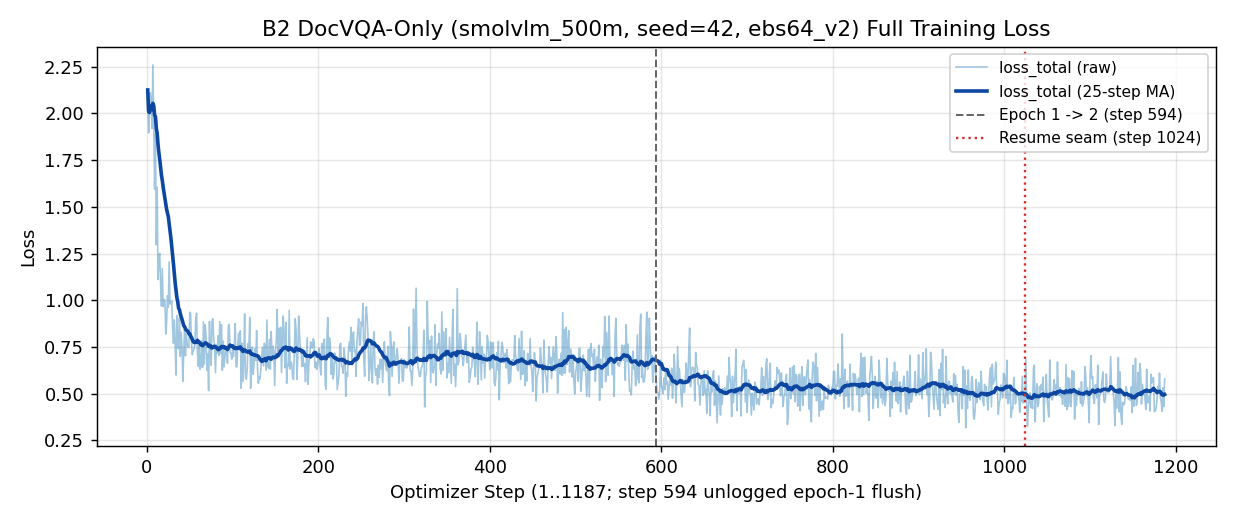

=== val_metrics.json ===
{
  "docvqa_anls": 0.658481,
  "docvqa_vqa_accuracy": 0.211822,
  "textvqa_anls": 0.545861,
  "textvqa_vqa_accuracy": 0.381702,
  "harmonic_mean": 0.483268,
  "selection_score": 0.658481
}
=== Delta vs Z0 (validation) ===
  docvqa_anls: 0.6585 (Z0: 0.0059, delta: +0.6525)
  textvqa_vqa_accuracy: 0.3817 (Z0: 0.1963, delta: +0.1854)
  harmonic_mean: 0.4833 (Z0: 0.0115, delta: +0.4717)
=== run_card.yaml ===
experiment:
  id: B2_smolvlm_500m_seed42
  exp: B2
  seed: 42
  git_sha: ef5d35b
data:
  regime: alt_three_splits
  revision: three-splits
  few_shot_pct: 100
  include_ocr: false
model:
  backbone: HuggingFaceTB/SmolVLM-500M-Base
  architecture_mode: standard_lora
  lora_r: 16
  lora_alpha: 32
training:
  hardware_profile: t4_16gb
  checkpoint_namespace: ebs64_v2
  per_device_train_batch_size: 8
  gradient_accumulation_steps: 8
  effective_batch_size: 64
  epochs: 2
  lr: 0.0004
  elapsed_sec: 14697.36
evaluation_results:
  docvqa_anls: 0.658481
  docvqa_vqa_a

In [7]:
# ==============================================================================
# 5. INSPECT B1 RESULTS & UNATTENDED SYNC (DRIVE + OPTIONAL GITHUB)
# ==============================================================================
import json
import os
import shutil
import subprocess
import time
from pathlib import Path
import yaml

_t0 = time.perf_counter()

_exp = globals().get("EXP", "B1")
_model = globals().get("MODEL_KEY", "smolvlm_500m")
_seed = int(globals().get("SEED", 42))
_ocr_tag = "_ocr" if globals().get("INCLUDE_OCR", False) else ""
_exp_folder = {"B1": "B1_target_only", "B2": "B2_source_only"}[_exp] + _ocr_tag

_cfg = yaml.safe_load(Path("TRAIN/ALT_THREE_SPLITS/configs/baselines_B1_B5.yaml").read_text(encoding="utf-8"))
_ns = (_cfg.get("checkpoints", {}).get("checkpoint_namespace") or "").strip().strip("/")
_parts = [_model, _ns, _exp_folder, f"seed_{_seed}"] if _ns else [_model, _exp_folder, f"seed_{_seed}"]
run_dir = Path(_cfg["runs_root"]).joinpath(*_parts)
print(f"Inspecting run directory: {run_dir}")

# 5A. Training log summary & inline loss curve
train_log_p = run_dir / "train_log.jsonl"
if train_log_p.exists():
    rows = [json.loads(line) for line in train_log_p.read_text(encoding="utf-8").splitlines() if line.strip()]
    if rows:
        last = rows[-1]
        print(
            f"train_log.jsonl: {len(rows)} steps logged | "
            f"latest epoch={last.get('epoch')} step={last.get('opt_step')} "
            f"loss={last.get('loss_total', float('nan')):.4f} "
            f"lr={last.get('lr', 0.0):.2e} mem={last.get('gpu_mem_gb', 0.0):.2f} GB"
        )
        try:
            import matplotlib.pyplot as plt

            xs = list(range(1, len(rows) + 1))
            ys = [r.get("loss_total", float("nan")) for r in rows]
            fig, ax = plt.subplots(figsize=(7, 3))
            ax.plot(xs, ys, linewidth=1.2, label="loss_total")
            ax.set_title(f"{_exp} ({_model}, seed={_seed}) Training Loss")
            ax.set_xlabel("Logged Optimizer Step")
            ax.set_ylabel("Loss")
            ax.grid(True, alpha=0.3)
            ax.legend()
            plt.tight_layout()
            plt.show()
        except Exception:
            pass
else:
    print("train_log.jsonl not found yet.")

# 5B. Validation metrics (with optional delta vs Z0 anchor) & run card
val_p = run_dir / "val_metrics.json"
if val_p.exists():
    val_data = json.loads(val_p.read_text(encoding="utf-8"))
    print("=== val_metrics.json ===")
    print(json.dumps(val_data, indent=2))
    z0_p = Path(_cfg["runs_root"]) / _model / "Z0" / "val_metrics.json"
    if z0_p.exists():
        z0_raw = json.loads(z0_p.read_text(encoding="utf-8"))
        z0_val = z0_raw.get("splits", {}).get("validation", z0_raw)
        cur_val = val_data.get("splits", {}).get("validation", val_data)
        print("=== Delta vs Z0 (validation) ===")
        for k in ("docvqa_anls", "textvqa_vqa_accuracy", "harmonic_mean"):
            if k in cur_val and k in z0_val:
                print(f"  {k}: {cur_val[k]:.4f} (Z0: {z0_val[k]:.4f}, delta: {cur_val[k] - z0_val[k]:+.4f})")
else:
    print("val_metrics.json not found yet (run may have paused before epoch-end eval).")

card_p = run_dir / "run_card.yaml"
if card_p.exists():
    print("=== run_card.yaml ===")
    print(card_p.read_text(encoding="utf-8")[:1500])

ckpt_dir = run_dir / "checkpoints"
if ckpt_dir.exists():
    ckpts = sorted(p.name for p in ckpt_dir.iterdir() if p.is_dir())
    print(f"Local checkpoints in {ckpt_dir}: {ckpts}")

# 5C. Resolve Google Drive backup dir safely (even if Cell 5 is run independently)
_gdrive_dir = globals().get("GDRIVE_BACKUP_DIR")
if not _gdrive_dir and Path("/content/drive/MyDrive").exists():
    _default_drive = Path("/content/drive/MyDrive/CrossVQA_Checkpoints/ALT_THREE_SPLITS")
    _default_drive.mkdir(parents=True, exist_ok=True)
    _gdrive_dir = str(_default_drive)

# Mirror lightweight logs/cards to Google Drive (excluding heavy checkpoints/)
if _gdrive_dir:
    drive_runs = Path(_gdrive_dir) / "runs_logs"
    drive_runs.mkdir(parents=True, exist_ok=True)
    shutil.copytree(
        "TRAIN/ALT_THREE_SPLITS/runs",
        drive_runs,
        dirs_exist_ok=True,
        ignore=shutil.ignore_patterns("checkpoints", "*.safetensors", "*.pt", "*.pth", "*.bin", "*.ckpt"),
    )
    print(f"Mirrored lightweight run logs to {drive_runs} (checkpoints excluded)")

# 5D. Optional unattended GitHub push for lightweight JSON/YAML/JSONL run artifacts
PUSH_LOGS_TO_GITHUB = True  # Set True when ready to commit logs from Colab
if PUSH_LOGS_TO_GITHUB:
    status = subprocess.run(
        ["git", "status", "--porcelain", "TRAIN/ALT_THREE_SPLITS/runs/"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    if status:
        subprocess.run(["git", "add", "TRAIN/ALT_THREE_SPLITS/runs/"], check=True)
        subprocess.run(
            ["git", "commit", "-m", f"chore(runs): sync {_exp} ({_model}, seed {_seed}) training logs"],
            check=True,
        )

    gh_token = os.environ.get("GH_TOKEN")
    if gh_token:
        remote_url = f"https://{gh_token}@github.com/NhanChanDeo/VQA_Final_Thesis.git"
        subprocess.run(["git", "fetch", remote_url, "main"], check=True)
        ahead = int(subprocess.run(
            ["git", "rev-list", "--count", "FETCH_HEAD..HEAD"],
            capture_output=True, text=True, check=True,
        ).stdout.strip() or "0")
        if ahead > 0:
            subprocess.run(["git", "rebase", "FETCH_HEAD"], check=True)
            subprocess.run(["git", "push", remote_url, "HEAD:main"], check=True)
            print("Synced lightweight logs to origin/main.")
        else:
            print("No new run artifacts to push.")
    elif status:
        print("GH_TOKEN not set; committed locally only.")

STAGE_TIMINGS = globals().get("STAGE_TIMINGS", {})
STAGE_TIMINGS["sync_sec"] = round(time.perf_counter() - _t0, 2)

In [8]:
# ==============================================================================
# 6. COMPUTE ECONOMY SUMMARY & SAFE DELAYED AUTO-DISCONNECT (300s)
# ==============================================================================
import time

AUTO_DISCONNECT = True            # Automatically release Colab GPU after delay
DISCONNECT_DELAY_SEC = 300        # 5-minute grace window before runtime.unassign()
REQUIRE_EXPLICIT_CONFIRM = True  # True -> manual y/N prompt (blocks unattended runs!)

_prep = STAGE_TIMINGS.get("prep_sec", 0.0) + STAGE_TIMINGS.get("auth_sec", 0.0) + STAGE_TIMINGS.get("snapshot_sec", 0.0)
_train = STAGE_TIMINGS.get("train_sec", 0.0)
_sync = STAGE_TIMINGS.get("sync_sec", 0.0)
_total = max(_prep + _train + _sync, 1e-6)
print(
    f"Compute Summary -> Prep/Snapshot: {_prep:.1f}s | Train/Eval: {_train:.1f}s ({100.0 * _train / _total:.1f}%) "
    f"| Sync: {_sync:.1f}s | Total: {_total:.1f}s | Run Succeeded: {globals().get('RUN_SUCCEEDED', True)}"
)

def _flush_drive_and_unassign():
    try:
        from google.colab import drive
        if Path("/content/drive/MyDrive").exists():
            drive.flush_and_unmount()
            print("Flushed Google Drive buffers.")
    except Exception:
        pass
    try:
        from google.colab import runtime
        print("Disconnecting and unassigning Colab runtime now...")
        runtime.unassign()
    except ImportError:
        print("Not running in Google Colab runtime; skipping runtime.unassign().")

if REQUIRE_EXPLICIT_CONFIRM:
    ans = input("Disconnect Colab runtime now? [y/N]: ").strip().lower()
    if ans in ("y", "yes"):
        _flush_drive_and_unassign()
    else:
        print("Keeping runtime alive.")
elif AUTO_DISCONNECT:
    _state = {"cancelled": False, "now": False}
    try:
        import ipywidgets as widgets
        from IPython.display import display

        _status = widgets.HTML(value=f"<b>Auto-disconnecting in {DISCONNECT_DELAY_SEC}s...</b>")
        _btn_cancel = widgets.Button(description="Cancel Auto-Disconnect", button_style="warning")
        _btn_now = widgets.Button(description="Disconnect Now", button_style="danger")

        def _on_cancel(_):
            _state["cancelled"] = True
            _status.value = "<b>Auto-disconnect cancelled; keeping runtime alive.</b>"

        def _on_now(_):
            _state["now"] = True
            _status.value = "<b>Disconnecting immediately...</b>"

        _btn_cancel.on_click(_on_cancel)
        _btn_now.on_click(_on_now)
        display(widgets.HBox([_btn_cancel, _btn_now, _status]))

        for _rem in range(DISCONNECT_DELAY_SEC, 0, -1):
            if _state["cancelled"] or _state["now"]:
                break
            _status.value = f"<b>Auto-disconnecting in {_rem}s...</b> (click Cancel to keep VM)"
            time.sleep(1)
    except Exception:
        print(f"Auto-disconnecting in {DISCONNECT_DELAY_SEC}s (interrupt cell to cancel)...")
        time.sleep(DISCONNECT_DELAY_SEC)

    if not _state["cancelled"]:
        _flush_drive_and_unassign()
else:
    print("AUTO_DISCONNECT=False; runtime left active.")

Compute Summary -> Prep/Snapshot: 149.8s | Train/Eval: 15412.9s (99.0%) | Sync: 3.2s | Total: 15565.9s | Run Succeeded: True
Disconnect Colab runtime now? [y/N]: y
Flushed Google Drive buffers.
Disconnecting and unassigning Colab runtime now...
